# ✏️ SketchesToLife — reproducible Colab run

This notebook reproduces the project end to end on a **GPU runtime**:

* **Google Colab:** *Runtime ▸ Change runtime type ▸ T4 GPU*. If Colab answers *"No backend
  with GPU available"*, free GPUs are temporarily exhausted: try again later, or use Kaggle.
  Never continue on a CPU runtime; the notebook stops if it has no GPU.
* **Kaggle** (free, about 30 GPU hours/week, phone-verified account): *File ▸ Import Notebook*,
  then in the right panel set *Accelerator: GPU T4 x2* and *Internet: on*.

Steps:

1. clone the repo and install the pinned dependencies
2. run the environment check
3. preprocess the sketches into control maps
4. **reproduce the hero figure** with the exact E6 configs and seed (42)
5. *(optional)* regenerate every figure in `results/` with `scripts/reproduce.sh`, and
   compare its SHA-256 manifest with a previous run
6. *(optional)* launch the Gradio app with a public `share=True` link

Every step is idempotent, so it is safe to re-run cells after a runtime restart.
Determinism caveats are listed at the end of the notebook.

In [1]:
#@title ⚙️ Settings
REPO_URL = "https://github.com/Wajid011/SketchesToLife.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
SAVE_TO_DRIVE = True  #@param {type:"boolean"}
RUN_FULL_REPRODUCTION = True  #@param {type:"boolean"}
LAUNCH_GRADIO_APP = False  #@param {type:"boolean"}


# Works on Google Colab and on Kaggle (Settings ▸ Accelerator: GPU T4 x2, Internet: on).
import os
# Kaggle first, from its own environment; only then Colab (the import must really work).
ON_KAGGLE = any(k in os.environ for k in ("KAGGLE_KERNEL_RUN_TYPE", "KAGGLE_URL_BASE"))     or os.path.isdir("/kaggle/working")
ON_COLAB = False
if not ON_KAGGLE:
    try:
        import google.colab  # noqa: F401
        ON_COLAB = True
    except ImportError:
        pass
WORK = "/kaggle/working" if ON_KAGGLE else "/content"
REPO_DIR = f"{WORK}/SketchesToLife"
DRIVE_DIR = "/content/drive/MyDrive/sketch2image"
if not ON_COLAB:
    SAVE_TO_DRIVE = False  # Kaggle keeps /kaggle/working as the notebook's output
print("Platform:", "Colab" if ON_COLAB else "Kaggle" if ON_KAGGLE else "other", "| work dir:", WORK)

Platform: Kaggle | work dir: /kaggle/working


## 1 · Clone and install

In [2]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
import os, subprocess, sys

if "<your-username>" in REPO_URL:
    raise ValueError("Set REPO_URL in the Settings cell to your GitHub repository first.")

# Without a GPU the pipeline silently falls back to placeholder ("mock") images,
# which would overwrite results/ with fakes, so stop here instead.
if subprocess.run(["nvidia-smi"], capture_output=True).returncode != 0:
    raise RuntimeError(
        "No GPU in this runtime. Colab: Runtime > Change runtime type > T4 GPU "
        "(if Colab says no GPU is available, try again later or use Kaggle). "
        "Kaggle: Settings > Accelerator > GPU T4 x2. Do not continue on CPU.")
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

if os.path.isdir(f"{REPO_DIR}/.git"):
    !git -C {REPO_DIR} fetch -q origin {BRANCH} && git -C {REPO_DIR} checkout -q {BRANCH} && git -C {REPO_DIR} pull -q --ff-only
else:
    !git clone -q --branch {BRANCH} {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!git log -1 --format="Commit %h  (%cd)  %s" --date=short

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.178.04
Tesla T4, 15360 MiB, 580.178.04
/kaggle/working/SketchesToLife
Commit 6270eec  (2026-11-19)  fix(t2i-adapter): feed the sketch adapter a grayscale control map


In [3]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
# Pinned stack from requirements.txt (diffusers 0.27.2, transformers 4.40.2, ...).
# Colab's preinstalled torch is kept; the exact versions are recorded in step 2.
%cd {REPO_DIR}
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps

# requirements.txt pins numpy 1.26; if Colab had numpy 2.x already imported, the
# runtime must restart once to load the pinned version. This cell does it for you;
# afterwards, simply run the notebook again from the top (installs are then no-ops).
import importlib.metadata, numpy
installed = importlib.metadata.version("numpy")
if numpy.__version__ != installed:
    print(f"numpy {numpy.__version__} loaded but {installed} installed -> restarting runtime…")
    os.kill(os.getpid(), 9)
print("Dependencies ready. numpy", numpy.__version__)

/kaggle/working/SketchesToLife
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sketch2image (pyproject.toml) ... done
Dependencies ready. numpy 2.1.3


In [4]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
if SAVE_TO_DRIVE:  # Colab only (forced off elsewhere in Settings)
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    os.environ["OUTPUT_DIR"] = DRIVE_DIR

## 2 · Environment check

In [5]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
%cd {REPO_DIR}
!python scripts/check_env.py

/kaggle/working/SketchesToLife
/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.13/dist-packages/controlnet_aux/segment_anything/modeling/tiny_vit_sam.py:654: UserWarning: Overwriting tiny_vit_5m_224 in regi

## 3 · Preprocess the sketches

Each sketch is cleaned (illumination normalisation, adaptive threshold, speck removal)
and converted into the control map ControlNet receives. The grids show raw → cleaned → Canny.

/kaggle/working/SketchesToLife
Found 3 sketch(es) in 'sketches'.
Processing modes: ['clean', 'canny'] at resolution 512x512...

Processing: sketch_01.jpg
  ✓ clean      -> outputs/conditions/sketch_01_clean.png
  ✓ canny      -> outputs/conditions/sketch_01_canny.png
  ★ Comparison grid saved: outputs/conditions/sketch_01_grid.png

Processing: sketch_02.jpg
  ✓ clean      -> outputs/conditions/sketch_02_clean.png
  ✓ canny      -> outputs/conditions/sketch_02_canny.png
  ★ Comparison grid saved: outputs/conditions/sketch_02_grid.png

Processing: sketch_03.jpg
  ✓ clean      -> outputs/conditions/sketch_03_clean.png
  ✓ canny      -> outputs/conditions/sketch_03_canny.png
  ★ Comparison grid saved: outputs/conditions/sketch_03_grid.png

outputs/conditions/sketch_01_grid.png


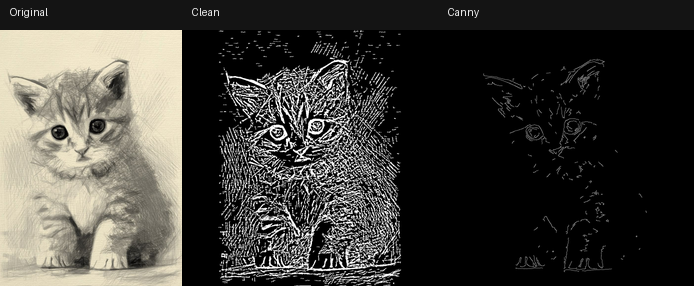

outputs/conditions/sketch_02_grid.png


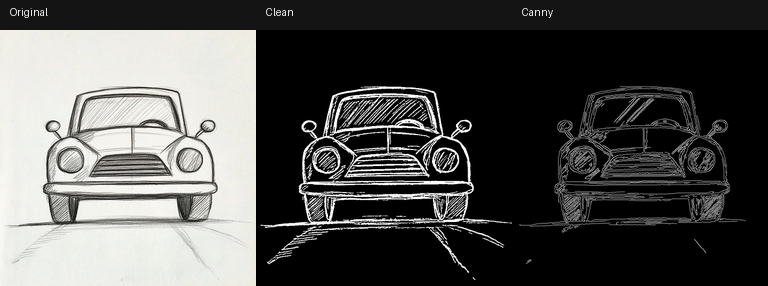

outputs/conditions/sketch_03_grid.png


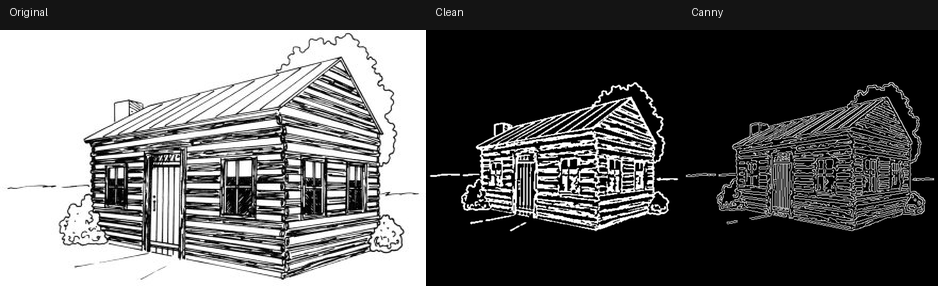

In [6]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
%cd {REPO_DIR}
!PYTHONPATH=src python -m sketch2image.preprocessing --input sketches --out outputs/conditions --modes clean,canny

from IPython.display import Image as IPImage, display
import glob
for grid in sorted(glob.glob("outputs/conditions/*_grid.png")):
    print(grid); display(IPImage(grid, width=900))

## 4 · Reproduce the hero figure

The hero figure pairs each sketch with one E6 (style preset) output. Its configuration is
fixed in code and YAML: SD 1.5 + ControlNet **scribble**, conditioning scale 1.0, CFG 7.5,
30 steps, DPM++ 2M Karras, 512 px, **seed 42**; presets photorealistic / concept_art /
watercolor. The cell below prints the config it runs, generates E6 into a fresh folder
(no reuse of earlier images), and rebuilds `results/hero_comparison.png`.

/kaggle/working/SketchesToLife
# Experiment E6: Style Preset & Artistic Domain Variation
id: E6
title: Style Preset & Artistic Variation
description: >
  Showcases creative versatility by applying 5 completely different aesthetic
  and material domains (Photorealistic, Architectural Render, Concept Art,
  Watercolor, Cyberpunk) to the exact same input sketch.

fixed:
  backend: sd15_controlnet
  controlnet_type: scribble
  condition_mode: clean
  num_inference_steps: 30
  guidance_scale: 7.5
  controlnet_conditioning_scale: 1.0
  seed: 42
  resolution: 512
  scheduler: "DPM++ 2M Karras"

sweep:
  type: scalar_sweep
  parameter: preset
  values:
    - photorealistic
    - architectural_render
    - concept_art
    - watercolor
    - cyberpunk
  labels:
    - "Photorealistic"
    - "Arch Render"
    - "Concept Art"
    - "Watercolor"
    - "Cyberpunk"
  SketchesToLife — Experimentation Framework
  Target Experiments: ['E6']
  Sketches Found:     ['sketch_01.jpg', 'sketch_02.jpg', 'sketch

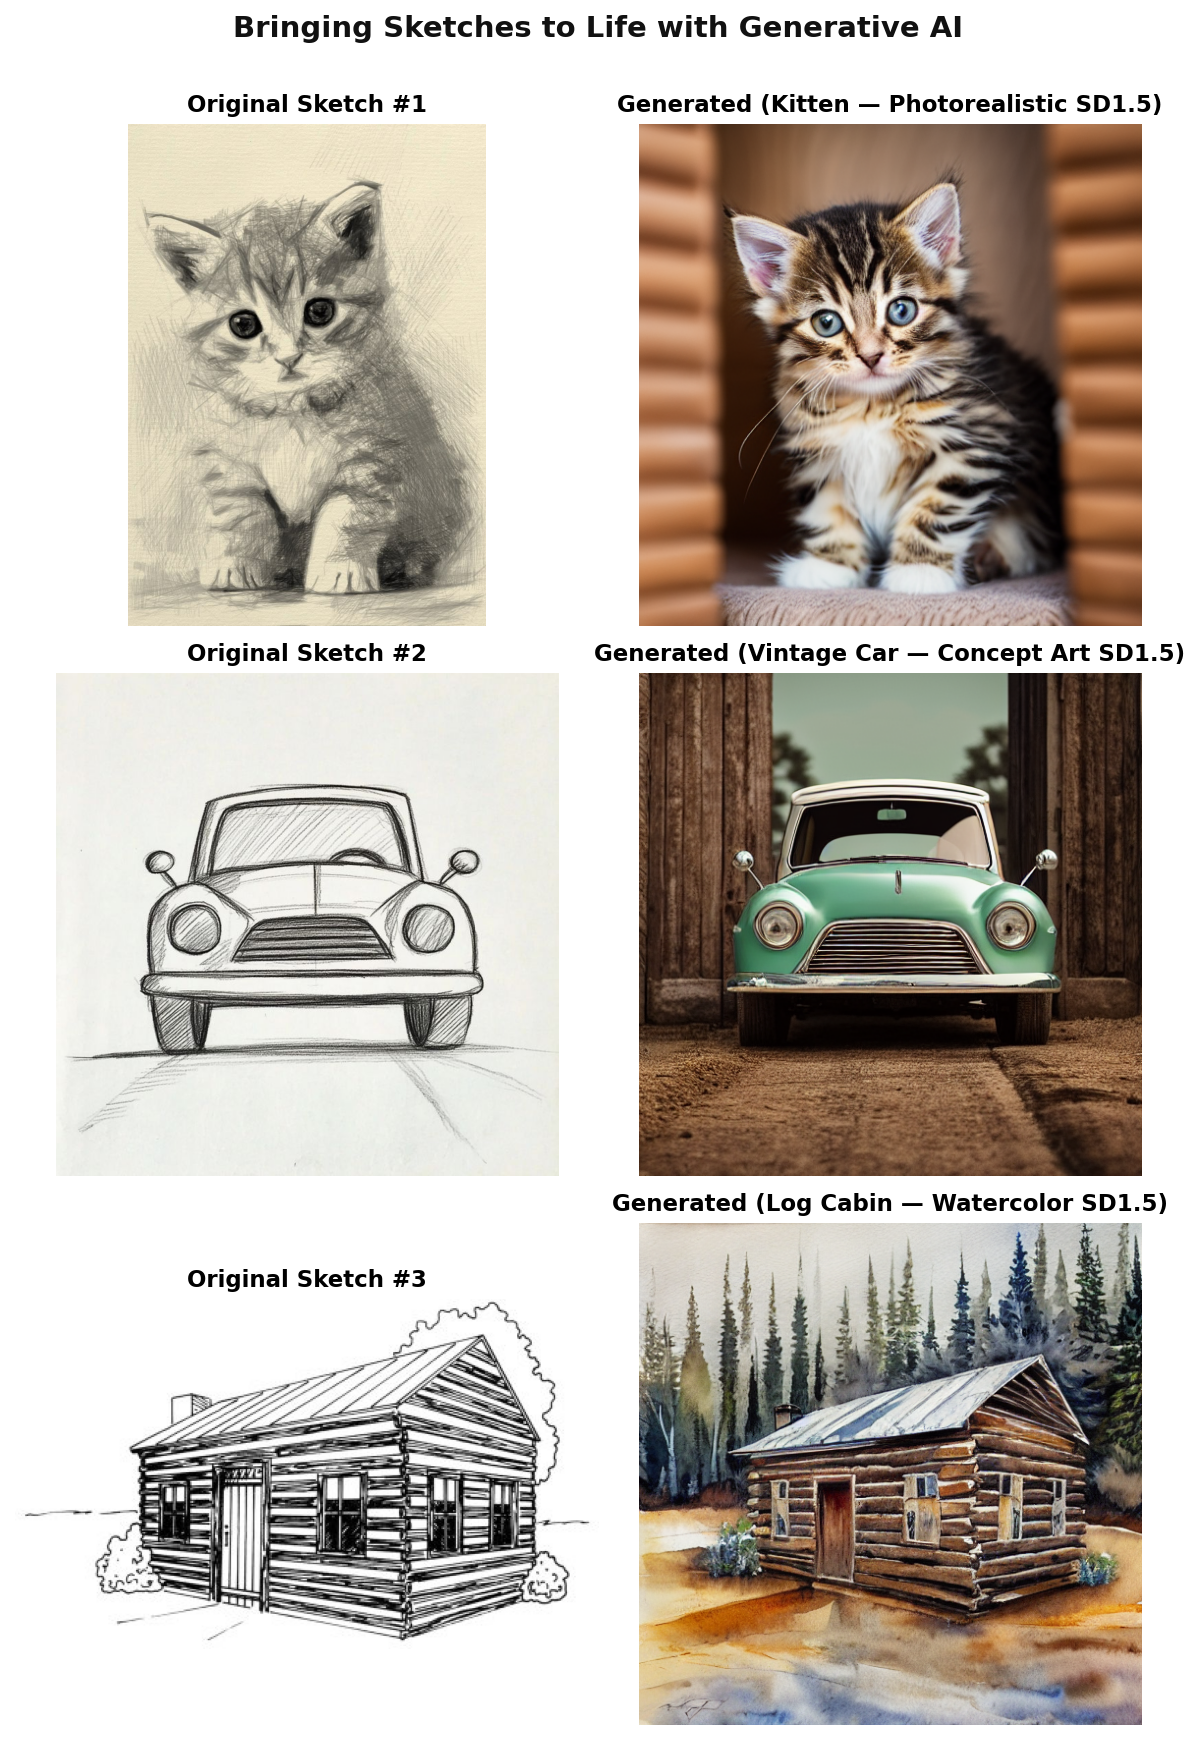

In [7]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
%cd {REPO_DIR}
!cat configs/experiments/e6_styles.yaml
!rm -rf outputs/hero_repro /tmp/hero_ok
!PYTHONHASHSEED=0 CUBLAS_WORKSPACE_CONFIG=:4096:8 python scripts/run_experiments.py -e E6 --out-dir outputs/hero_repro/experiments --results-dir results && touch /tmp/hero_ok

# Only show the figure if THIS run succeeded (results/ may hold an older one).
if not os.path.exists("/tmp/hero_ok"):
    raise RuntimeError("The hero run failed: scroll up to the first error message.")
display(IPImage("results/hero_comparison.png", width=700))

In [8]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
# Per-image record: seed, model IDs, runtime and peak VRAM are stored next to every output.
import json, pathlib
for meta in sorted(pathlib.Path("outputs/hero_repro/experiments/E6").glob("*/*_meta.json"))[:3]:
    m = json.loads(meta.read_text())
    print(f"{meta.name}: seed={m['seed']} preset={m['style_preset']} "
          f"runtime={m['runtime_sec']}s vram={m['peak_vram_mb']:.0f}MB mock={m['mock']}")

sketch_01_architectural_render_sd15_controlnet_scribble_seed42_meta.json: seed=42 preset=architectural_render runtime=7.94s vram=3434MB mock=False
sketch_01_concept_art_sd15_controlnet_scribble_seed42_meta.json: seed=42 preset=concept_art runtime=7.99s vram=3434MB mock=False
sketch_01_cyberpunk_sd15_controlnet_scribble_seed42_meta.json: seed=42 preset=cyberpunk runtime=8.11s vram=3434MB mock=False


## 5 · *(optional)* Regenerate every figure + verify against a previous run

`scripts/reproduce.sh` wipes its scratch folder, reruns E1, E2 and E6 from the configs,
rebuilds all grids, the hero figure, `metrics.csv`, the plots and `ANALYSIS.md`, then writes
a SHA-256 manifest of every generated image and figure (`outputs/reproduce/checksums.sha256`).

If `SAVE_TO_DRIVE` is on, the manifest is kept on Drive **per GPU model**, and the next run on
the same GPU type is compared with it automatically.

/kaggle/working/SketchesToLife

==> Fresh output directory: outputs/reproduce

==> 1/5 Environment
/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.13/dist-packages/controlnet_aux/segment_anything/modeling/t

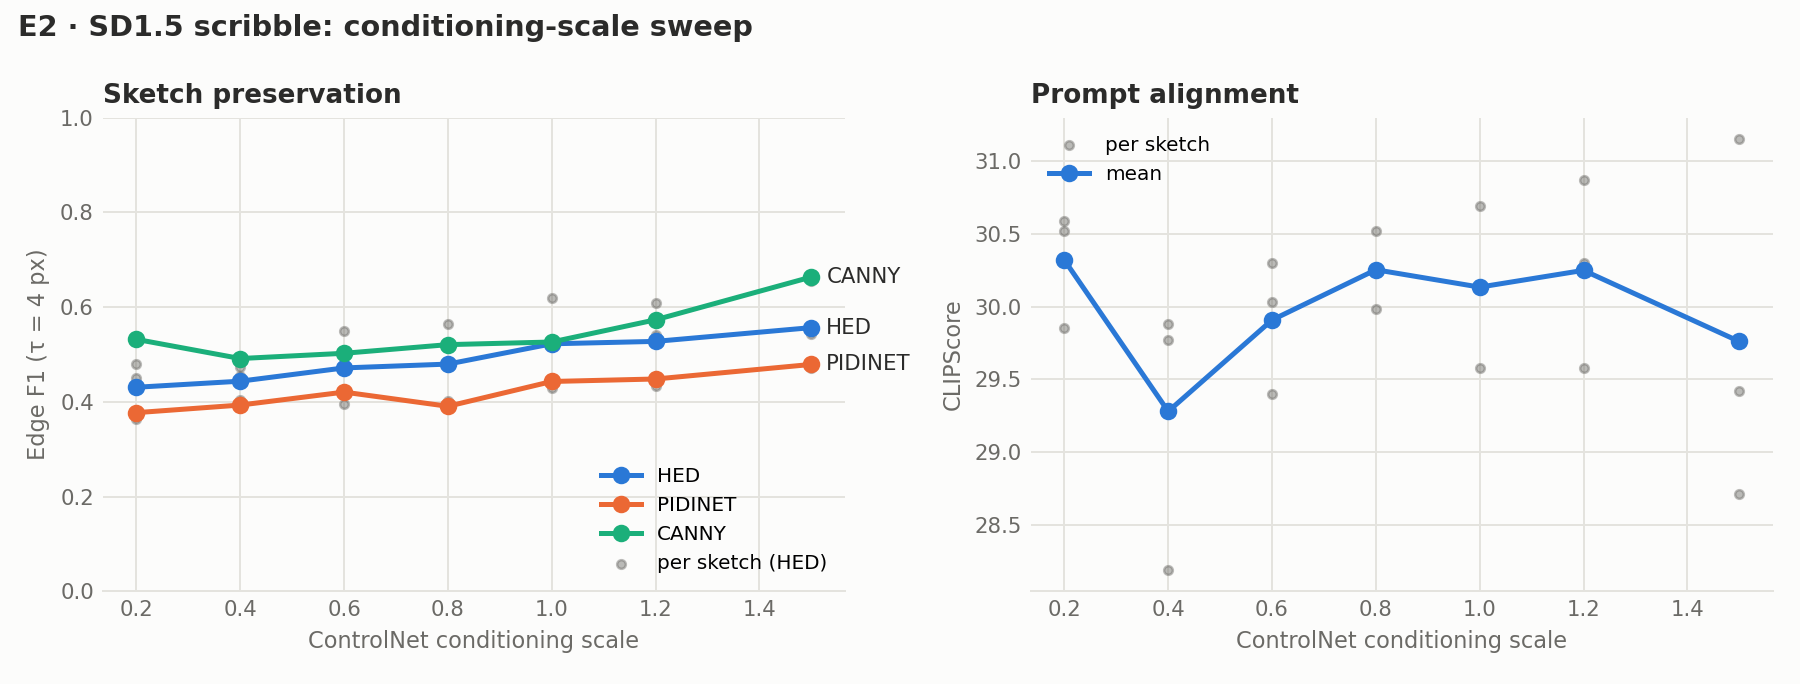

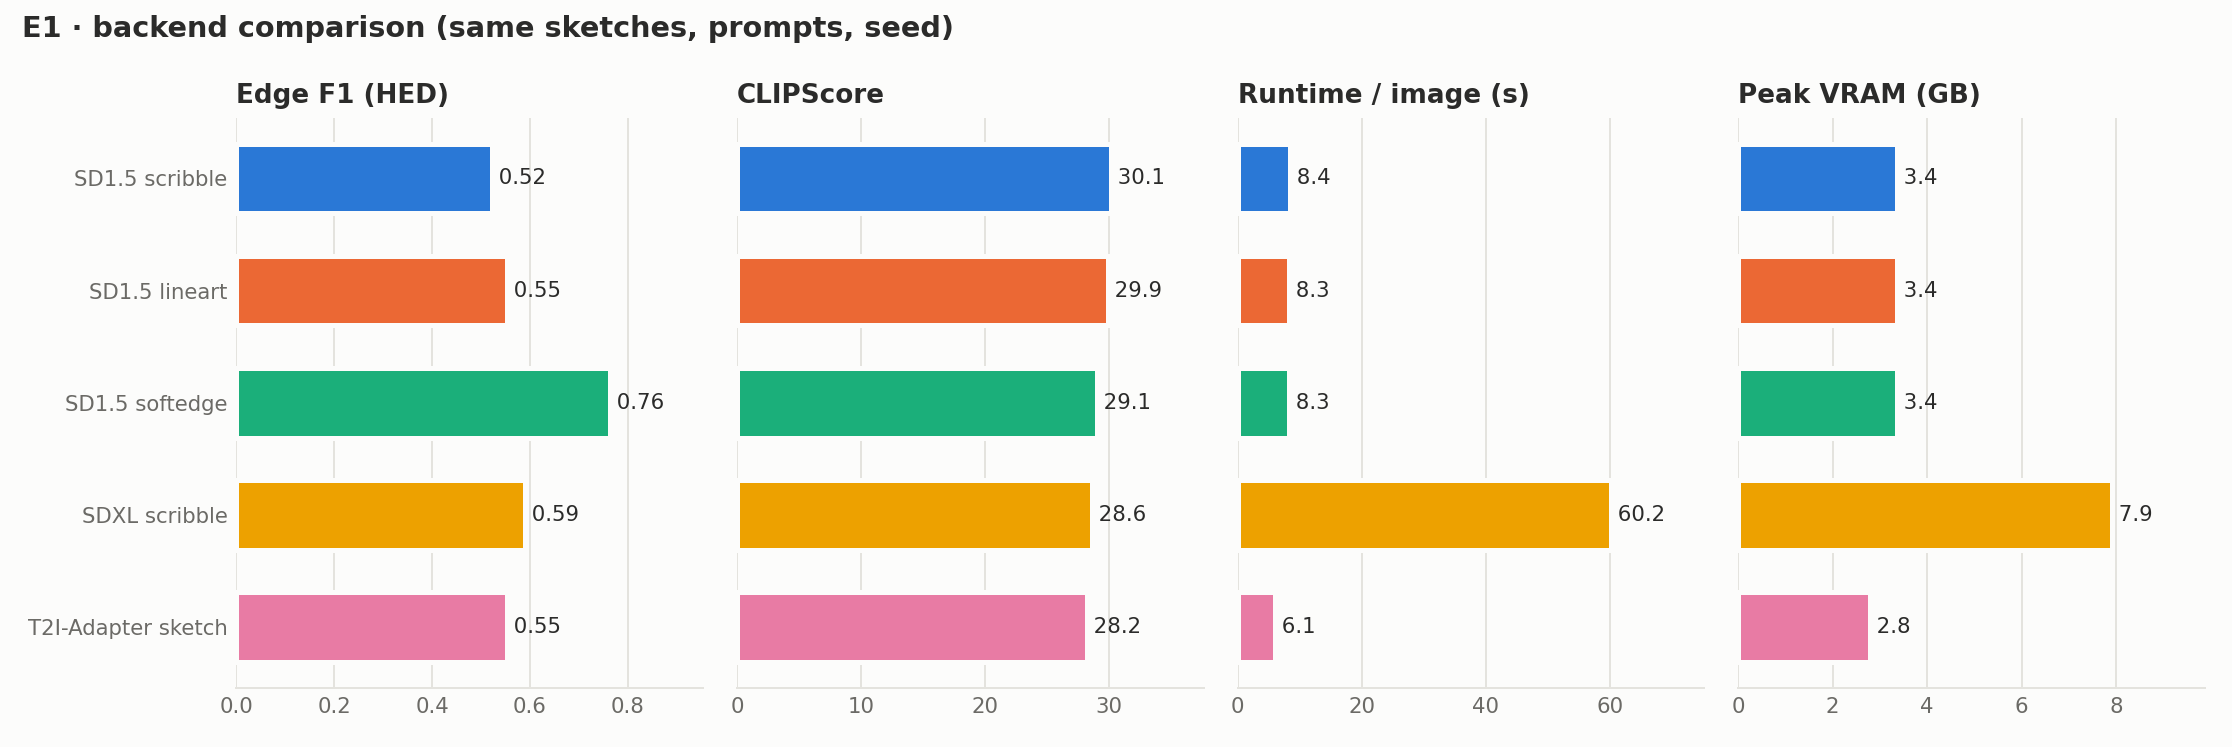

In [9]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
%cd {REPO_DIR}
if RUN_FULL_REPRODUCTION:
    !rm -f /tmp/repro_ok
    !bash scripts/reproduce.sh && touch /tmp/repro_ok
    # Only show figures if THIS run succeeded (results/ may hold older ones).
    if not os.path.exists("/tmp/repro_ok"):
        raise RuntimeError("The reproduction failed: scroll up to the first error message.")
    display(IPImage("results/scale_sweep.png", width=800))
    display(IPImage("results/backend_comparison.png", width=900))
else:
    print("Skipped (set RUN_FULL_REPRODUCTION = True in Settings).")

In [10]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
import shutil, torch, difflib
manifest = pathlib.Path("outputs/reproduce/checksums.sha256")
if RUN_FULL_REPRODUCTION and manifest.exists() and SAVE_TO_DRIVE:
    gpu = torch.cuda.get_device_name(0).replace(" ", "_") if torch.cuda.is_available() else "cpu"
    ref = pathlib.Path(DRIVE_DIR) / f"checksums_{gpu}_torch{torch.__version__.split('+')[0]}.sha256"
    if ref.exists():
        a = [l for l in ref.read_text().splitlines() if not l.startswith("#")]
        b = [l for l in manifest.read_text().splitlines() if not l.startswith("#")]
        changed = [l for l in difflib.unified_diff(a, b, lineterm="", n=0)
                   if l.startswith("+") and not l.startswith("+++")]
        print(f"Compared with {ref.name}: {len(b) - len(changed)}/{len(b)} files identical.")
        for l in changed[:20]:
            print("  differs:", l.split()[-1])
    else:
        shutil.copy(manifest, ref)
        print(f"No reference yet for this GPU/torch: saved {ref.name}. Re-run later to compare.")
else:
    print("Nothing to compare (needs RUN_FULL_REPRODUCTION and SAVE_TO_DRIVE).")

Nothing to compare (needs RUN_FULL_REPRODUCTION and SAVE_TO_DRIVE).


In [11]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
# Keep the figures and raw outputs after the Colab VM is recycled.
import shutil
if SAVE_TO_DRIVE:
    !mkdir -p {DRIVE_DIR}/results && cp -r results/. {DRIVE_DIR}/results/
    !for d in outputs/hero_repro outputs/reproduce; do [ -d "$d" ] && cp -r "$d" {DRIVE_DIR}/; done
    print("Copied to", DRIVE_DIR)

# One-file download of all figures/metrics on any platform:
# Colab: Files panel (left) > right-click > Download.  Kaggle: Output panel (right).
shutil.make_archive(f"{WORK}/sketchestolife_results", "zip", "results")
print("Results zip:", f"{WORK}/sketchestolife_results.zip")

Results zip: /kaggle/working/sketchestolife_results.zip


## 6 · *(optional)* Launch the Gradio app

Prints a public `https://….gradio.live` link (valid ~72 h). The cell keeps running while the
app is up; press ■ (stop) to shut it down.

In [12]:
if "REPO_DIR" not in globals():
    raise RuntimeError("The kernel restarted, so the settings are gone: run the notebook again from the top (Run All).")
%cd {REPO_DIR}
if LAUNCH_GRADIO_APP:
    !python app/app.py --share
else:
    print("Skipped (set LAUNCH_GRADIO_APP = True in Settings).")

/kaggle/working/SketchesToLife
Skipped (set LAUNCH_GRADIO_APP = True in Settings).


## Determinism caveats

* **Same GPU model + same library versions → identical images** is the expectation:
  the initial latent comes from a seeded `torch.Generator`, and `set_seed` enables cuDNN
  deterministic mode. The manifest check in step 5 tests exactly this.
* **Different GPU (T4 vs P100/A100) or a different torch/CUDA/diffusers version** changes
  floating-point kernels; fp16 rounding differences accumulate over 30 denoising steps, so
  images are *visually* very close but not bit-identical. Compare those runs by eye or with
  the metrics, not by hash.
* The app, the CLI and the experiments all draw the starting noise on the GPU, so the same
  settings and seed give the same image in each. SDXL's latent (128×128) has a different
  size from SD 1.5's (64×64), so a seed is not comparable across those two backends.
* The neural annotators (HED/PiDiNet) and CLIP used by `analyze.py` are deterministic in
  eval mode, but their scores inherit any image differences from above.
* `runtime_sec`, peak VRAM, `metrics.csv` and the runtime panel of `backend_comparison.png`
  are measurements, so they change on every run and are left out of the manifest.
* Colab updates its base image (torch, CUDA) over time; step 2 records the versions used,
  and the manifest reference on Drive is keyed by GPU model and torch version.